In [2]:
# -----------------------------
# HOUSE PRICE PREDICTION PROJECT
# -----------------------------

# Step 1: Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Step 2: Load Dataset
df = pd.read_csv("/content/data.csv")

print("Dataset Preview:\n", df.head())
print("\nDataset Info:\n")
print(df.info())

Dataset Preview:
                   date      price  bedrooms  bathrooms  sqft_living  sqft_lot  \
0  2014-05-02 00:00:00   313000.0       3.0       1.50         1340      7912   
1  2014-05-02 00:00:00  2384000.0       5.0       2.50         3650      9050   
2  2014-05-02 00:00:00   342000.0       3.0       2.00         1930     11947   
3  2014-05-02 00:00:00   420000.0       3.0       2.25         2000      8030   
4  2014-05-02 00:00:00   550000.0       4.0       2.50         1940     10500   

   floors  waterfront  view  condition  sqft_above  sqft_basement  yr_built  \
0     1.5           0     0          3        1340              0      1955   
1     2.0           0     4          5        3370            280      1921   
2     1.0           0     0          4        1930              0      1966   
3     1.0           0     0          4        1000           1000      1963   
4     1.0           0     0          4        1140            800      1976   

   yr_renovated     

In [4]:
# -----------------------------
# Step 3: Data Preprocessing
# -----------------------------

# Check missing values
print("\nMissing Values:\n", df.isnull().sum())

# Fill missing values
df = df.fillna(df.mean(numeric_only=True))

# Handle categorical data (yes/no, etc.)
categorical_cols = df.select_dtypes(include='object').columns
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)


Missing Values:
 date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
street           0
city             0
statezip         0
country          0
dtype: int64


In [5]:
# -----------------------------
# Step 4: Feature Selection
# -----------------------------
X = df.drop('price', axis=1).values
y = df['price'].values


In [6]:
# -----------------------------
# Step 5: Train-Test Split
# -----------------------------
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [7]:

# -----------------------------
# Step 6: Train Model
# -----------------------------
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [8]:
# -----------------------------
# Step 7: Prediction
# -----------------------------
y_pred = model.predict(X_test)

In [9]:
# -----------------------------
# Step 8: Model Evaluation
# -----------------------------
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n📊 Model Performance:")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score (Accuracy):", r2)


📊 Model Performance:
MAE : 305500.1021921502
MSE : 1157218002917.0317
RMSE: 1075740.6764257972
R2 Score (Accuracy): -0.13469839271900952


In [10]:
# -----------------------------
# Step 9: Coefficients
# -----------------------------
print("\nModel Coefficients:\n", model.coef_)
print("Intercept:", model.intercept_)


Model Coefficients:
 [-13224.44173568  32975.77313933    220.63590372 ...  72329.35618784
  26170.45798213  82542.6790679 ]
Intercept: 3422749.9082133947


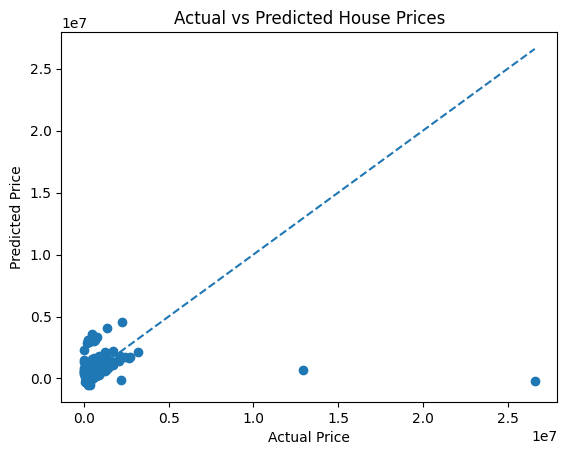

In [11]:
# -----------------------------
# Step 10: GRAPH 1
# Actual vs Predicted
# -----------------------------
plt.figure()

plt.scatter(y_test, y_pred)

# Ideal line (perfect prediction)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         linestyle='--')

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")

plt.show()


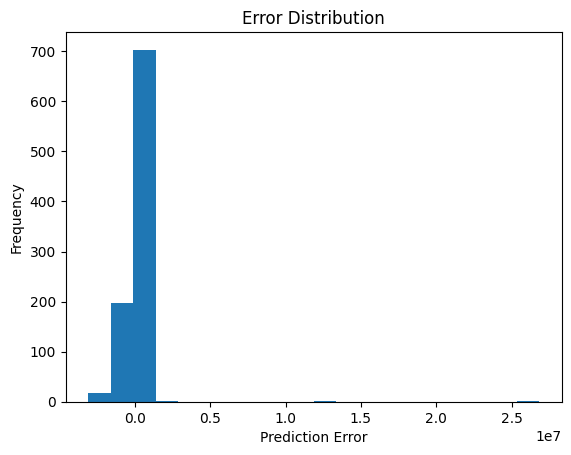

In [12]:
# -----------------------------
# Step 11: GRAPH 2
# Error Distribution
# -----------------------------
errors = y_test - y_pred

plt.figure()
plt.hist(errors, bins=20)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Error Distribution")

plt.show()

In [13]:
# -----------------------------
# Step 12: Prediction (Optional)
# -----------------------------
print("\nNOTE: Prediction input is skipped due to encoded features complexity.")

# If you want prediction, you must match encoded columns exactly.


NOTE: Prediction input is skipped due to encoded features complexity.
